# Predicción de lotes defectuosos con Machine Learning Supervisado
**Caso de estudio:** empresa manufacturera XYZ Inc.  
**Objetivo:** predecir si un lote saldrá defectuoso (1) o no defectuoso (0) a partir de temperatura, presión, velocidad, horas de operación y vibración.  
**Algoritmos:** Regresión Logística, Árbol de Decisión, Random Forest, SVM, KNN y Naive Bayes.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             fbeta_score, balanced_accuracy_score, matthews_corrcoef,
                             cohen_kappa_score, roc_auc_score, log_loss, roc_curve,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## 1. Dataset y exploración de datos

In [2]:
data = {
    "temperatura": [70,72,75,80,85,90,95,100,78,82,88,92,97,76,73,89,94,99,81,86],
    "presion": [30,32,34,36,40,42,45,48,35,37,41,43,46,33,31,42,44,47,36,39],
    "velocidad": [120,118,115,110,105,100,95,90,112,108,102,98,93,116,119,101,96,91,109,104],
    "horas_operacion": [2,3,4,6,8,10,12,14,5,7,9,11,13,4,3,10,12,15,6,8],
    "vibracion": [1.2,1.4,1.6,2.0,2.5,3.0,3.5,4.0,1.8,2.2,2.8,3.2,3.7,1.5,1.3,3.1,3.6,4.2,2.1,2.6],
    "defectuoso": [0,0,0,0,1,1,1,1,0,0,1,1,1,0,0,1,1,1,0,1],
}
df = pd.DataFrame(data)
print(df.head())
print("\nDimensiones:", df.shape)
print("\nDistribución de clases:\n", df["defectuoso"].value_counts())
print("\nEstadísticos descriptivos por clase:")
print(df.groupby("defectuoso").mean().round(2))

   temperatura  presion  velocidad  horas_operacion  vibracion  defectuoso
0           70       30        120                2        1.2           0
1           72       32        118                3        1.4           0
2           75       34        115                4        1.6           0
3           80       36        110                6        2.0           0
4           85       40        105                8        2.5           1

Dimensiones: (20, 6)

Distribución de clases:
 defectuoso
1    11
0     9
Name: count, dtype: int64

Estadísticos descriptivos por clase:
            temperatura  presion  velocidad  horas_operacion  vibracion
defectuoso                                                             
0                 76.33    33.78     114.11             4.44       1.68
1                 92.27    43.36      97.73            11.09       3.29


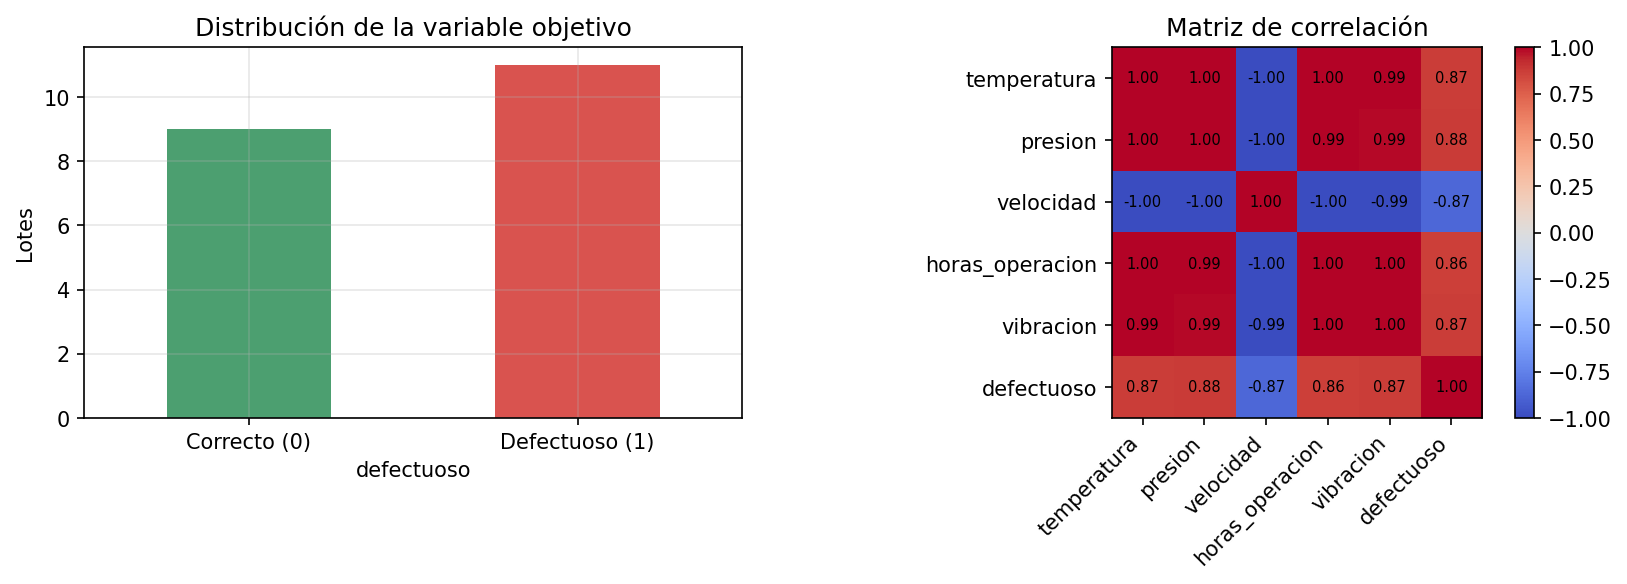

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
df["defectuoso"].value_counts().sort_index().plot(kind="bar", ax=axes[0], color=["#4C9F70", "#D9534F"])
axes[0].set_xticklabels(["Correcto (0)", "Defectuoso (1)"], rotation=0)
axes[0].set_title("Distribución de la variable objetivo"); axes[0].set_ylabel("Lotes")

corr = df.corr()
im = axes[1].imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
axes[1].set_xticks(range(len(corr))); axes[1].set_yticks(range(len(corr)))
axes[1].set_xticklabels(corr.columns, rotation=45, ha="right"); axes[1].set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        axes[1].text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
axes[1].set_title("Matriz de correlación"); axes[1].grid(False)
fig.colorbar(im, ax=axes[1], fraction=0.046)
plt.tight_layout(); plt.show()

## 2. Ejercicio de Regresión Logística
Primero, un modelo simple con una sola variable (temperatura) para visualizar la función sigmoide; luego el modelo múltiple.

Intercepto (b0) = -87.031
Coeficiente temperatura (b1) = 1.042
Odds ratio por +1 °C = 2.835


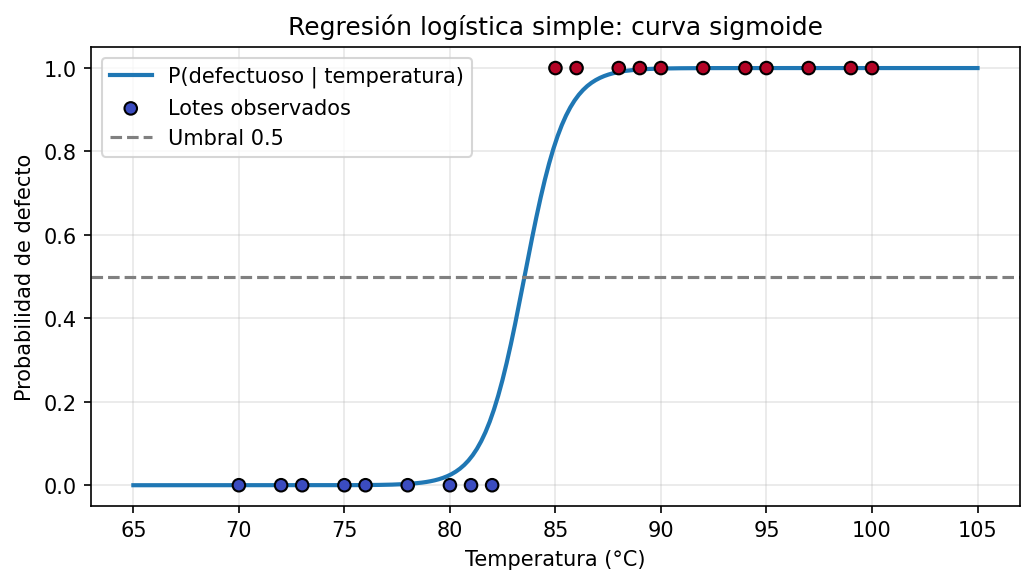

In [4]:
# 2.1 Regresión logística simple: temperatura -> probabilidad de defecto
X1 = df[["temperatura"]]; y = df["defectuoso"]
rl1 = LogisticRegression().fit(X1, y)
b0, b1 = rl1.intercept_[0], rl1.coef_[0][0]
print(f"Intercepto (b0) = {b0:.3f}")
print(f"Coeficiente temperatura (b1) = {b1:.3f}")
print(f"Odds ratio por +1 °C = {np.exp(b1):.3f}")

t = pd.DataFrame({"temperatura": np.linspace(65, 105, 200)})
p = rl1.predict_proba(t)[:, 1]
plt.figure(figsize=(7, 4))
plt.plot(t["temperatura"], p, color="#1f77b4", lw=2, label="P(defectuoso | temperatura)")
plt.scatter(df["temperatura"], y, c=y, cmap="coolwarm", edgecolor="k", zorder=3, label="Lotes observados")
plt.axhline(0.5, color="gray", ls="--", label="Umbral 0.5")
plt.xlabel("Temperatura (°C)"); plt.ylabel("Probabilidad de defecto")
plt.title("Regresión logística simple: curva sigmoide"); plt.legend()
plt.tight_layout(); plt.show()

## 3. Partición de datos y definición de modelos
Se usa 70 % entrenamiento / 30 % prueba con `stratify=y`. Los modelos sensibles a la escala (Regresión Logística, KNN y SVM) se envuelven en un *pipeline* con `StandardScaler`.

In [5]:
features = ["temperatura", "presion", "velocidad", "horas_operacion", "vibracion"]
X = df[features]; y = df["defectuoso"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y)
print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)
print("Clases en prueba:", y_test.value_counts().to_dict())

modelos = {
    "Regresión Logística": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Árbol de Decisión": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "SVM (lineal)": make_pipeline(StandardScaler(), SVC(kernel="linear", probability=True, random_state=42)),
    "KNN (k=3)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=3)),
    "Naive Bayes": GaussianNB(),
}

Entrenamiento: (14, 5) | Prueba: (6, 5)
Clases en prueba: {0: 3, 1: 3}


## 4. Entrenamiento y evaluación con todas las métricas

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
resultados, predicciones = [], {}

for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    y_pred = modelo.predict(X_test)
    y_prob = modelo.predict_proba(X_test)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()
    predicciones[nombre] = (y_pred, y_prob)

    cvr = cross_validate(modelo, X, y, cv=cv,
                         scoring=["accuracy", "precision", "recall", "f1", "roc_auc"])
    resultados.append({
        "Modelo": nombre, "TN": tn, "FP": fp, "FN": fn, "TP": tp,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "Especificidad": tn / (tn + fp),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "F2": fbeta_score(y_test, y_pred, beta=2, zero_division=0),
        "Balanced Acc": balanced_accuracy_score(y_test, y_pred),
        "MCC": matthews_corrcoef(y_test, y_pred),
        "Kappa": cohen_kappa_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "Log Loss": log_loss(y_test, y_prob, labels=[0, 1]),
        "CV Accuracy": cvr["test_accuracy"].mean(),
        "CV Precision": cvr["test_precision"].mean(),
        "CV Recall": cvr["test_recall"].mean(),
        "CV F1": cvr["test_f1"].mean(),
        "CV ROC-AUC": cvr["test_roc_auc"].mean(),
    })

res = pd.DataFrame(resultados).set_index("Modelo")
pd.set_option("display.width", 250); pd.set_option("display.max_columns", None)
print("=== Matriz de confusión (conjunto de prueba) ===")
print(res[["TN", "FP", "FN", "TP"]])
print("\n=== Métricas en el conjunto de prueba ===")
print(res[["Accuracy", "Precision", "Recall", "Especificidad", "F1", "F2",
           "Balanced Acc", "MCC", "Kappa", "ROC-AUC", "Log Loss"]].round(3))
print("\n=== Validación cruzada estratificada (5 folds) ===")
print(res[["CV Accuracy", "CV Precision", "CV Recall", "CV F1", "CV ROC-AUC"]].round(3))

=== Matriz de confusión (conjunto de prueba) ===
                     TN  FP  FN  TP
Modelo                             
Regresión Logística   3   0   0   3
Árbol de Decisión     3   0   0   3
Random Forest         3   0   0   3
SVM (lineal)          3   0   0   3
KNN (k=3)             3   0   0   3
Naive Bayes           3   0   0   3

=== Métricas en el conjunto de prueba ===
                     Accuracy  Precision  Recall  Especificidad   F1   F2  Balanced Acc  MCC  Kappa  ROC-AUC  Log Loss
Modelo                                                                                                                
Regresión Logística       1.0        1.0     1.0            1.0  1.0  1.0           1.0  1.0    1.0      1.0     0.114
Árbol de Decisión         1.0        1.0     1.0            1.0  1.0  1.0           1.0  1.0    1.0      1.0     0.000
Random Forest             1.0        1.0     1.0            1.0  1.0  1.0           1.0  1.0    1.0      1.0     0.007
SVM (lineal)             

In [7]:
for nombre in modelos:
    print("="*60); print(nombre); print("="*60)
    print(classification_report(y_test, predicciones[nombre][0],
                                target_names=["Correcto", "Defectuoso"], zero_division=0))

Regresión Logística
              precision    recall  f1-score   support

    Correcto       1.00      1.00      1.00         3
  Defectuoso       1.00      1.00      1.00         3

    accuracy                           1.00         6
   macro avg       1.00      1.00      1.00         6
weighted avg       1.00      1.00      1.00         6

Árbol de Decisión
              precision    recall  f1-score   support

    Correcto       1.00      1.00      1.00         3
  Defectuoso       1.00      1.00      1.00         3

    accuracy                           1.00         6
   macro avg       1.00      1.00      1.00         6
weighted avg       1.00      1.00      1.00         6

Random Forest
              precision    recall  f1-score   support

    Correcto       1.00      1.00      1.00         3
  Defectuoso       1.00      1.00      1.00         3

    accuracy                           1.00         6
   macro avg       1.00      1.00      1.00         6
weighted avg       1.0

## 5. Visualizaciones

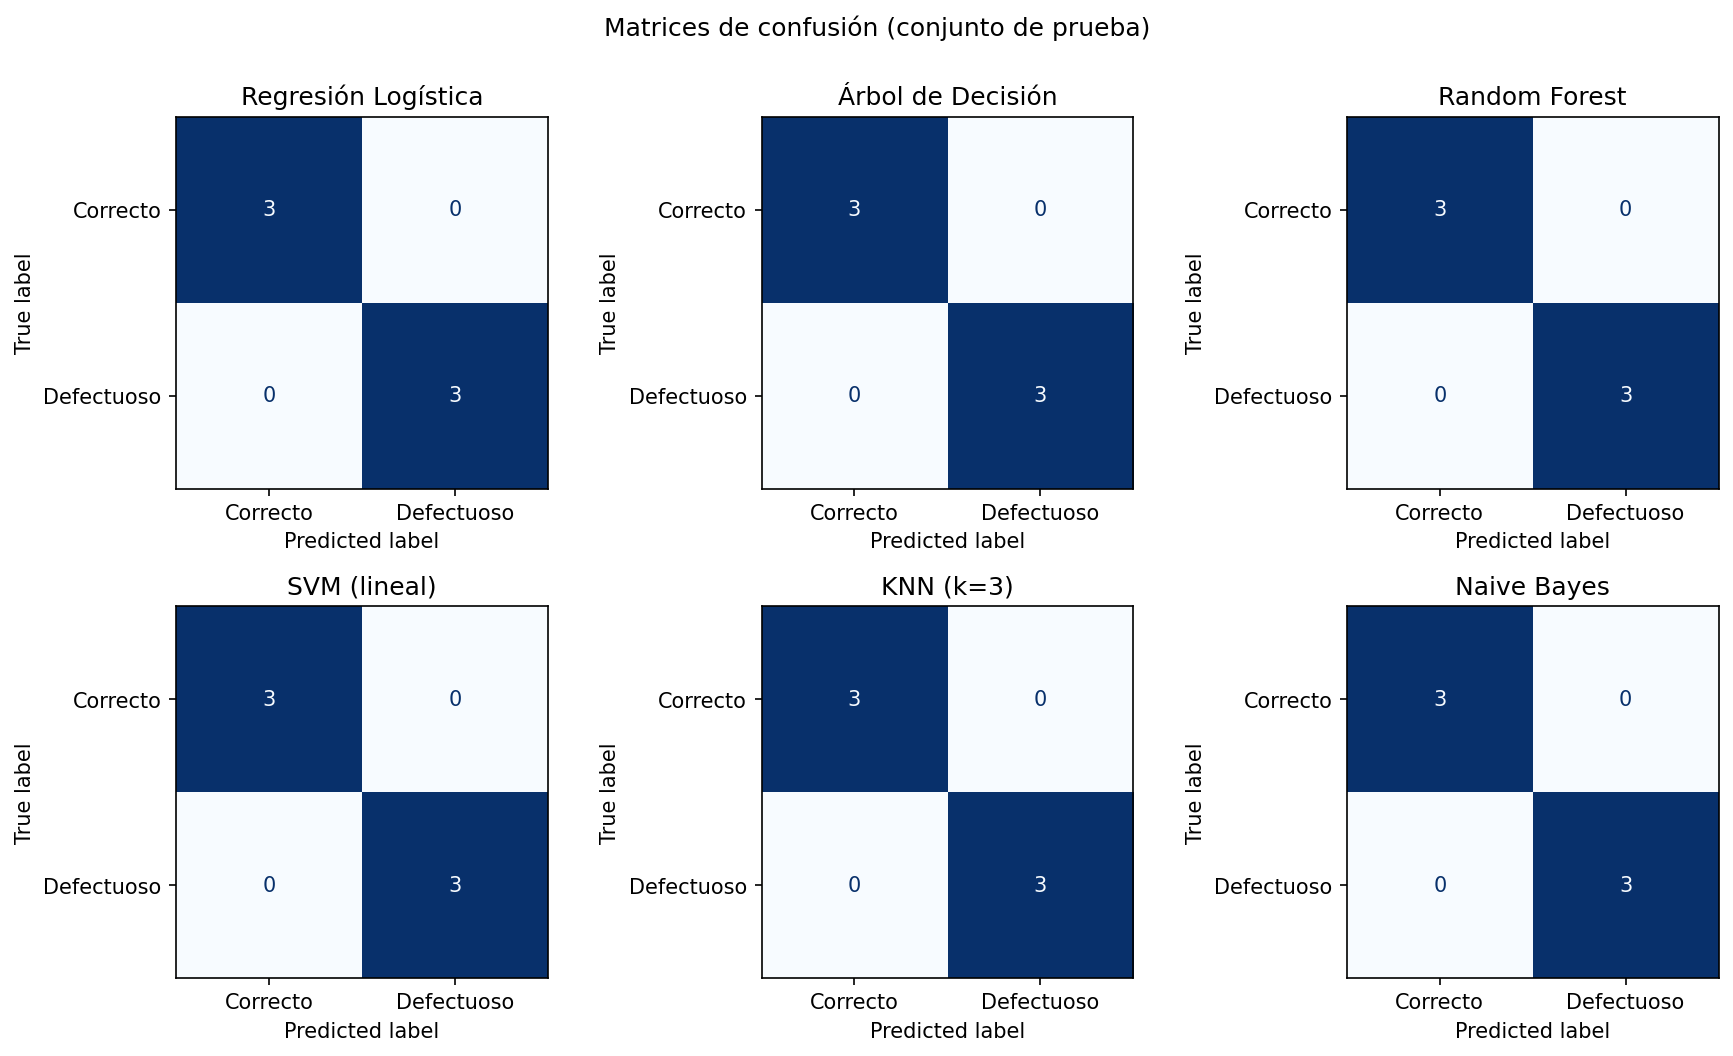

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, (nombre, (y_pred, _)) in zip(axes.ravel(), predicciones.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, labels=[0, 1]),
                           display_labels=["Correcto", "Defectuoso"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(nombre); ax.grid(False)
plt.suptitle("Matrices de confusión (conjunto de prueba)", y=1.0)
plt.tight_layout(); plt.show()

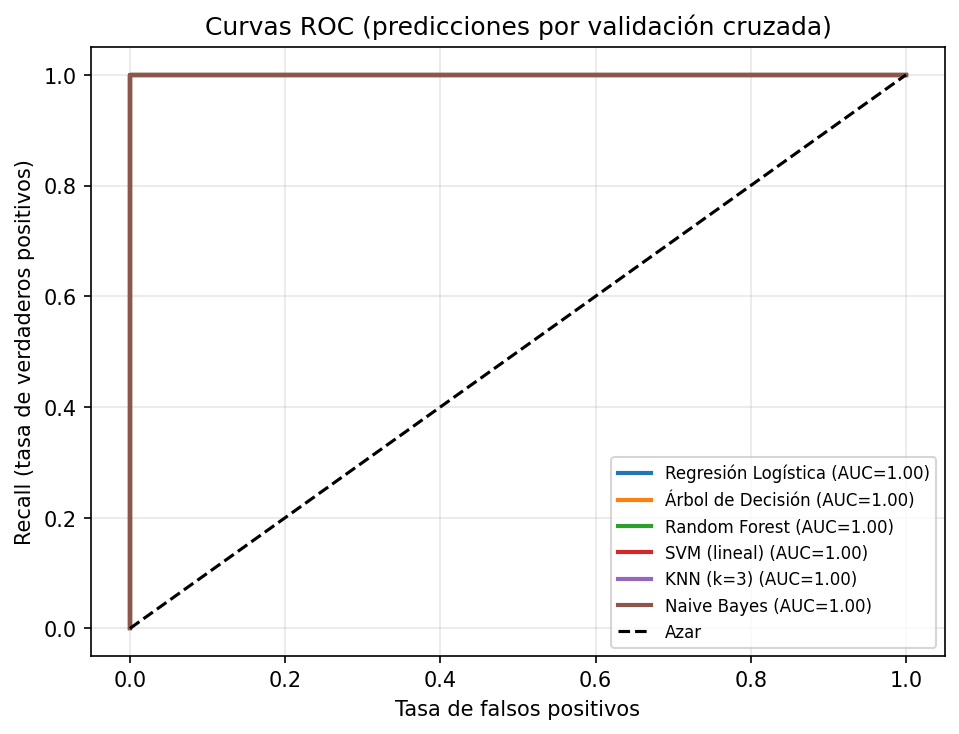

In [9]:
# Curvas ROC sobre TODO el dataset con validación cruzada (más informativas que 6 lotes de prueba)
from sklearn.model_selection import cross_val_predict
plt.figure(figsize=(6.5, 5))
for nombre, modelo in modelos.items():
    prob = cross_val_predict(modelo, X, y, cv=cv, method="predict_proba")[:, 1]
    fpr, tpr, _ = roc_curve(y, prob)
    plt.plot(fpr, tpr, lw=2, label=f"{nombre} (AUC={roc_auc_score(y, prob):.2f})")
plt.plot([0, 1], [0, 1], "k--", label="Azar")
plt.xlabel("Tasa de falsos positivos"); plt.ylabel("Recall (tasa de verdaderos positivos)")
plt.title("Curvas ROC (predicciones por validación cruzada)"); plt.legend(fontsize=8)
plt.tight_layout(); plt.show()

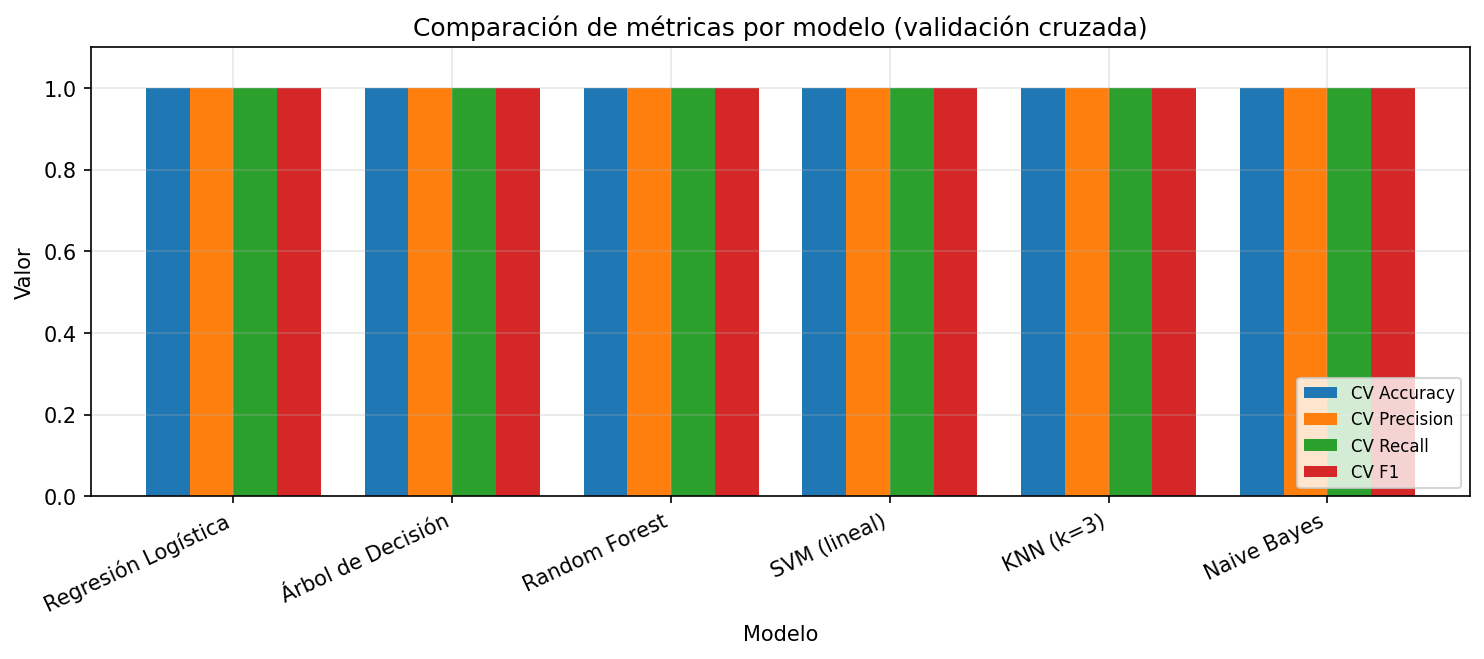

In [10]:
# Comparación de métricas principales (validación cruzada)
cols = ["CV Accuracy", "CV Precision", "CV Recall", "CV F1"]
res[cols].plot(kind="bar", figsize=(10, 4.5), width=0.8)
plt.ylim(0.0, 1.1); plt.ylabel("Valor"); plt.xticks(rotation=25, ha="right")
plt.title("Comparación de métricas por modelo (validación cruzada)")
plt.legend(loc="lower right", fontsize=8); plt.tight_layout(); plt.show()

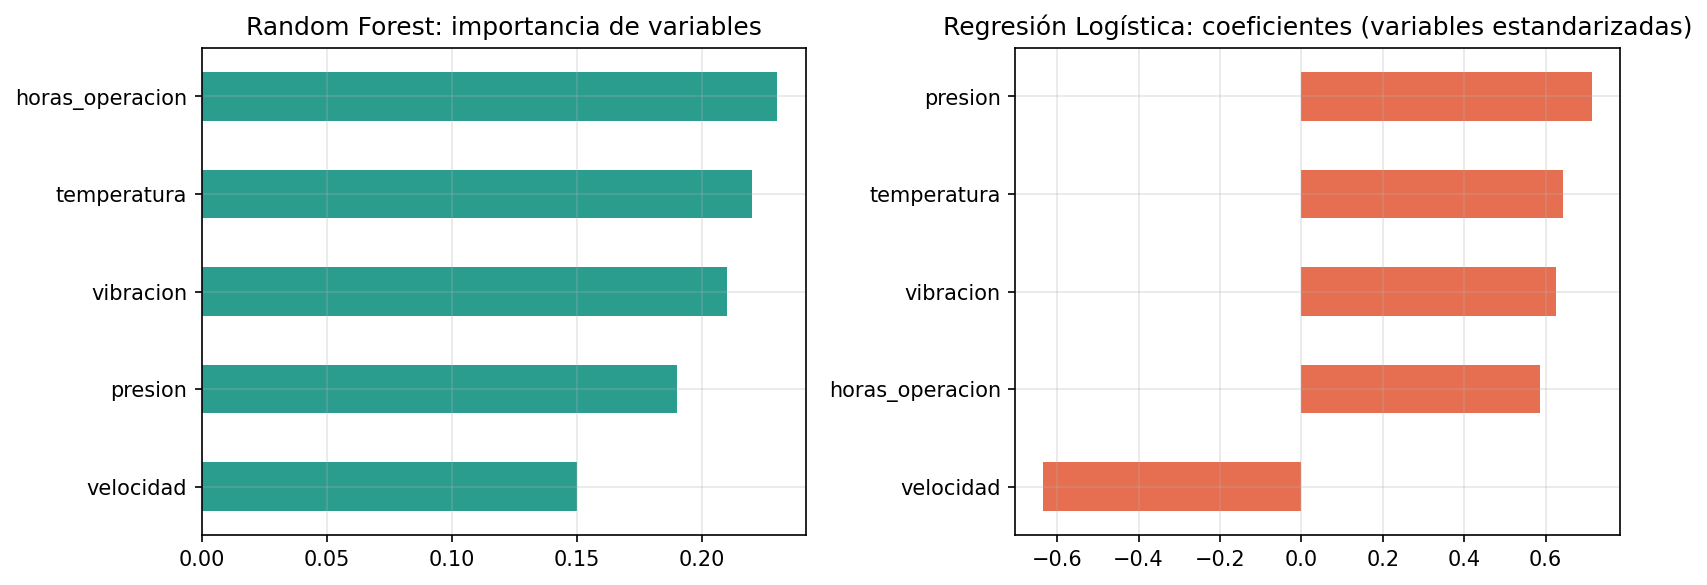

In [11]:
# Importancia de variables en Random Forest y coeficientes de la Regresión Logística
rf = modelos["Random Forest"]
lr = modelos["Regresión Logística"].named_steps["logisticregression"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
pd.Series(rf.feature_importances_, index=features).sort_values().plot(kind="barh", ax=axes[0], color="#2a9d8f")
axes[0].set_title("Random Forest: importancia de variables")
pd.Series(lr.coef_[0], index=features).sort_values().plot(kind="barh", ax=axes[1], color="#e76f51")
axes[1].set_title("Regresión Logística: coeficientes (variables estandarizadas)")
plt.tight_layout(); plt.show()

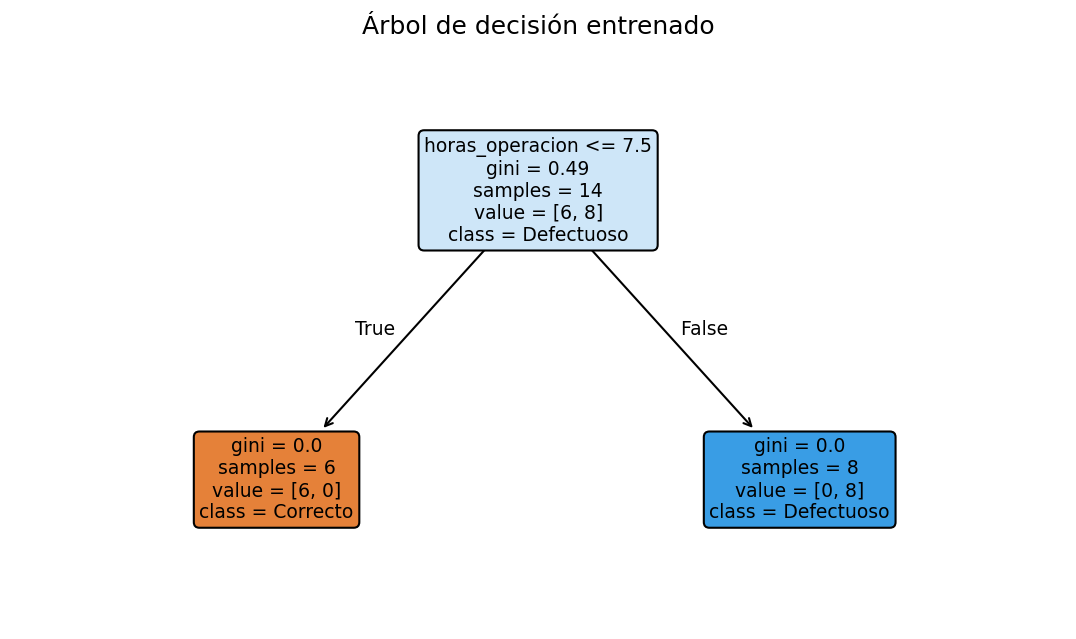

In [12]:
plt.figure(figsize=(9, 5))
plot_tree(modelos["Árbol de Decisión"], feature_names=features,
          class_names=["Correcto", "Defectuoso"], filled=True, rounded=True, fontsize=9)
plt.title("Árbol de decisión entrenado"); plt.show()

## 6. Selección del mejor modelo
Criterio del caso: priorizar **Recall** (evitar falsos negativos), desempatar con F2, Recall en validación cruzada y F1.

In [13]:
ranking = res.sort_values(by=["Recall", "F2", "CV Recall", "CV F1"], ascending=False)
print(ranking[["Recall", "F2", "CV Recall", "CV F1", "Precision", "FN", "FP"]].round(3))

                     Recall   F2  CV Recall  CV F1  Precision  FN  FP
Modelo                                                               
Regresión Logística     1.0  1.0        1.0    1.0        1.0   0   0
Árbol de Decisión       1.0  1.0        1.0    1.0        1.0   0   0
Random Forest           1.0  1.0        1.0    1.0        1.0   0   0
SVM (lineal)            1.0  1.0        1.0    1.0        1.0   0   0
KNN (k=3)               1.0  1.0        1.0    1.0        1.0   0   0
Naive Bayes             1.0  1.0        1.0    1.0        1.0   0   0
